In [1]:
import json, time, torch
from PIL import Image
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.transforms.functional import to_tensor

d = json.load(open("instances_val2017.json"))
imgs = d["images"][:100]
ids = {im["id"] for im in imgs}
gt = {i: [] for i in ids}
for a in d["annotations"]:
    if a["image_id"] in ids and not a["iscrowd"]:
        x, y, w, h = a["bbox"]
        gt[a["image_id"]].append([x, y, x + w, y + h])

model = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT).eval()
dets, times = {}, []
with torch.no_grad():
    for k, im in enumerate(imgs):
        img = Image.open("images/" + im["file_name"]).convert("RGB")
        t = time.time()
        out = model([to_tensor(img)])[0]
        times.append(time.time() - t)
        dets[im["id"]] = {"boxes": out["boxes"].tolist(), "scores": out["scores"].tolist()}
        if k % 10 == 0:
            print(k, flush=True)

json.dump({"gt": gt, "dets": dets, "times": times}, open("frcnn_results.json", "w"))
print("avg sec/img:", sum(times) / len(times))

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\MC/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|████████████████████████████████████████████████████████████████████████████████| 160M/160M [02:53<00:00, 964kB/s]


0
10
20
30
40
50
60
70
80
90
avg sec/img: 24.578086845874786


In [4]:
import json, time, torch
from PIL import Image
from transformers import DetrImageProcessor, DetrForObjectDetection

d = json.load(open("instances_val2017.json"))
imgs = d["images"][:100]
proc = DetrImageProcessor.from_pretrained("facebook/detr-resnet-50")
model = DetrForObjectDetection.from_pretrained("facebook/detr-resnet-50").eval()
print("model loaded", flush=True)

dets, times = {}, []
with torch.no_grad():
    for k, im in enumerate(imgs):
        img = Image.open("images/" + im["file_name"]).convert("RGB")
        t = time.time()
        inp = proc(images=img, return_tensors="pt")
        out = model(**inp)
        res = proc.post_process_object_detection(
            out, threshold=0.0, target_sizes=torch.tensor([img.size[::-1]])
        )[0]
        times.append(time.time() - t)
        dets[im["id"]] = {"boxes": res["boxes"].tolist(), "scores": res["scores"].tolist()}
        if k % 10 == 0:
            print(k, flush=True)
            json.dump({"dets": dets, "times": times}, open("detr_results.json", "w"))

json.dump({"dets": dets, "times": times}, open("detr_results.json", "w"))
print("avg sec/img:", sum(times) / len(times))

Loading weights: 100%|██████████████████████████████████████████████████████████████| 530/530 [00:01<00:00, 365.26it/s]
[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model loaded
0
10
20
30
40
50
60
70
80
90
avg sec/img: 12.94815239429474


In [6]:
import torchvision
from transformers import DetrForObjectDetection

frcnn = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None)
detr = DetrForObjectDetection.from_pretrained("facebook/detr-resnet-50")

n_fr = sum(p.numel() for p in frcnn.parameters())
n_de = sum(p.numel() for p in detr.parameters())
print(f"Faster R-CNN: {n_fr/1e6:.1f}M parameters")
print(f"DETR        : {n_de/1e6:.1f}M parameters")

Loading weights: 100%|██████████████████████████████████████████████████████████████| 530/530 [00:00<00:00, 604.11it/s]
[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Faster R-CNN: 41.8M parameters
DETR        : 41.5M parameters


GT counts: {'small': 195, 'medium': 213, 'large': 242}
Faster R-CNN found: {'small': 104, 'medium': 171, 'large': 215}
DETR found        : {'small': 120, 'medium': 176, 'large': 220}
Faster R-CNN recall: {'small': 0.533, 'medium': 0.803, 'large': 0.888}
DETR recall        : {'small': 0.615, 'medium': 0.826, 'large': 0.909}


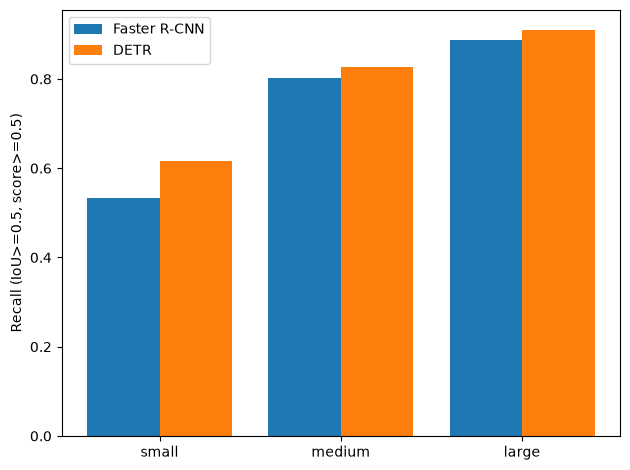

In [9]:
import json
import matplotlib.pyplot as plt

fr = json.load(open("frcnn_results.json"))
de = json.load(open("detr_results.json"))
gt = fr["gt"]

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0

def size_of(b):
    area = (b[2]-b[0]) * (b[3]-b[1])
    if area < 1024:
        return "small"
    if area < 9216:
        return "medium"
    return "large"

def recall(dets, thr=0.5):
    found = {"small": 0, "medium": 0, "large": 0}
    total = {"small": 0, "medium": 0, "large": 0}
    for img_id, boxes in gt.items():
        d = dets[img_id]
        keep = [b for b, s in zip(d["boxes"], d["scores"]) if s >= thr]
        for g in boxes:
            k = size_of(g)
            total[k] += 1
            if any(iou(g, b) >= 0.5 for b in keep):
                found[k] += 1
    return found, total

f_fr, total = recall(fr["dets"])
f_de, unused = recall(de["dets"])
sizes = ["small", "medium", "large"]
r_fr = {s: f_fr[s] / total[s] for s in sizes}
r_de = {s: f_de[s] / total[s] for s in sizes}

print("GT counts:", total)
print("Faster R-CNN found:", f_fr)
print("DETR found        :", f_de)
print("Faster R-CNN recall:", {s: round(r_fr[s], 3) for s in sizes})
print("DETR recall        :", {s: round(r_de[s], 3) for s in sizes})

x = [0, 1, 2]
plt.bar([i - 0.2 for i in x], [r_fr[s] for s in sizes], 0.4, label="Faster R-CNN")
plt.bar([i + 0.2 for i in x], [r_de[s] for s in sizes], 0.4, label="DETR")
plt.xticks(x, sizes)
plt.ylabel("Recall (IoU>=0.5, score>=0.5)")
plt.legend()
plt.tight_layout()
plt.savefig("recall_by_size.png", dpi=150)
plt.show()

In [2]:
import os
os.chdir(r"C:\Users\MC\detr-small-objects\data")
print(os.getcwd())
print(os.path.exists("frcnn_results.json"))
print(os.path.exists("detr_results.json"))
print(os.path.exists("images"))

C:\Users\MC\detr-small-objects\data
True
True
True


small GT found by both: 94 | only Faster R-CNN: 10 | only DETR: 26 | neither: 65


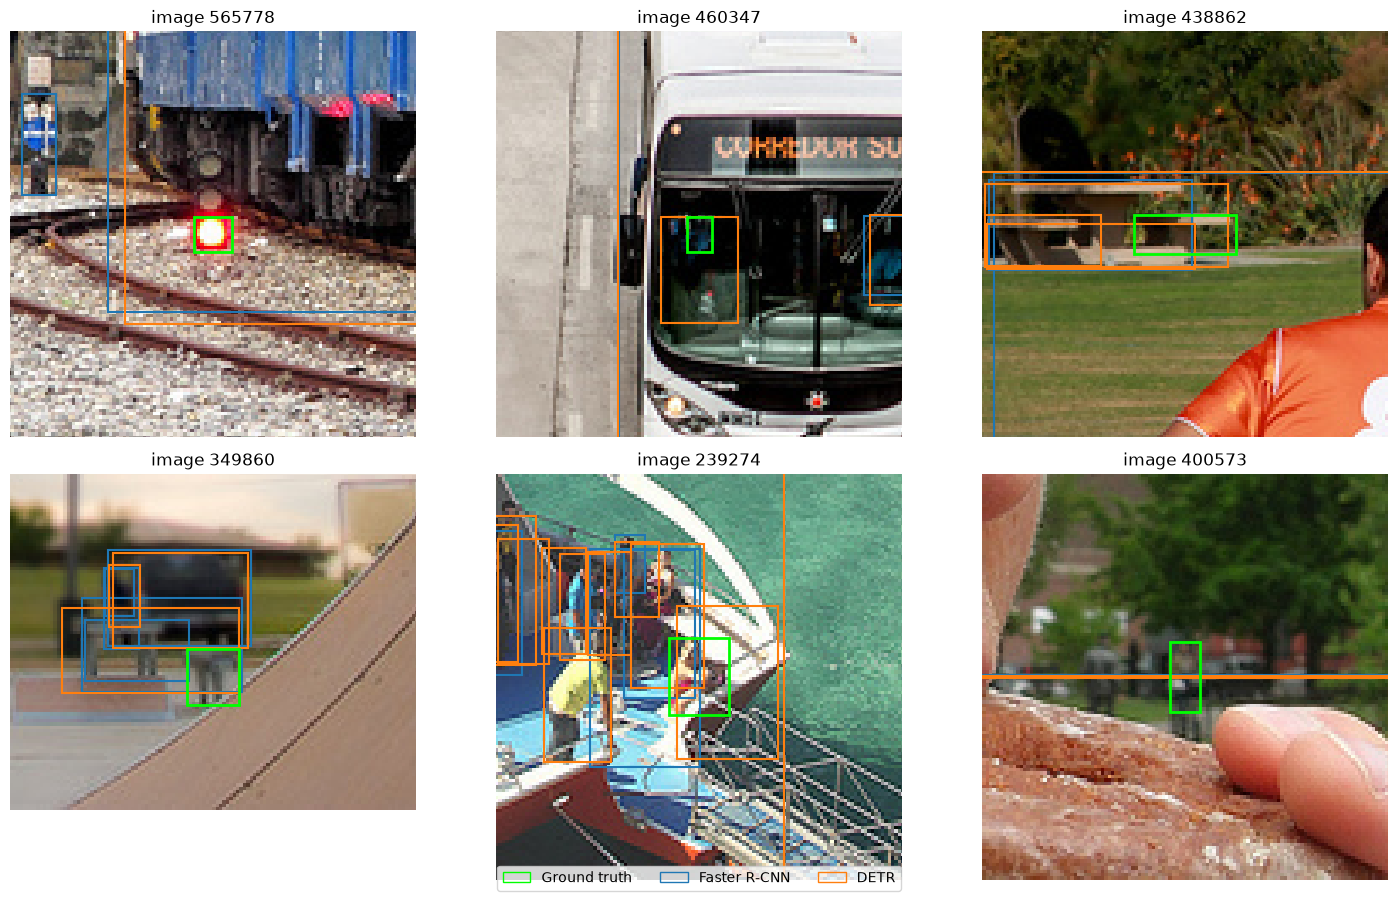

In [3]:
import os, json
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image

fr = json.load(open("frcnn_results.json"))
de = json.load(open("detr_results.json"))
gt = fr["gt"]

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0

def keep_boxes(d, thr=0.5):
    return [b for b, s in zip(d["boxes"], d["scores"]) if s >= thr]

def is_small(b):
    return (b[2]-b[0]) * (b[3]-b[1]) < 1024

def num_id(k):
    return int(os.path.splitext(str(k))[0])

files = {}
for f in os.listdir("images"):
    stem = os.path.splitext(f)[0]
    if stem.isdigit():
        files[int(stem)] = os.path.join("images", f)

both, only_fr, only_de, neither = 0, 0, 0, []
for img_id, boxes in gt.items():
    kf = keep_boxes(fr["dets"][img_id])
    kd = keep_boxes(de["dets"][img_id])
    for g in boxes:
        if not is_small(g):
            continue
        hit_f = any(iou(g, b) >= 0.5 for b in kf)
        hit_d = any(iou(g, b) >= 0.5 for b in kd)
        if hit_f and hit_d:
            both += 1
        elif hit_f:
            only_fr += 1
        elif hit_d:
            only_de += 1
        else:
            neither.append((img_id, g))

print("small GT found by both:", both, "| only Faster R-CNN:", only_fr,
      "| only DETR:", only_de, "| neither:", len(neither))

picked, seen = [], set()
for img_id, g in neither:
    if img_id not in seen:
        picked.append((img_id, g))
        seen.add(img_id)
    if len(picked) == 6:
        break

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax in axes.flat:
    ax.axis("off")
for ax, (img_id, g) in zip(axes.flat, picked):
    im = Image.open(files[num_id(img_id)]).convert("RGB")
    ax.imshow(im)
    for bx in keep_boxes(fr["dets"][img_id]):
        ax.add_patch(plt.Rectangle((bx[0], bx[1]), bx[2]-bx[0], bx[3]-bx[1],
                                   fill=False, ec="tab:blue", lw=1.5))
    for bx in keep_boxes(de["dets"][img_id]):
        ax.add_patch(plt.Rectangle((bx[0], bx[1]), bx[2]-bx[0], bx[3]-bx[1],
                                   fill=False, ec="tab:orange", lw=1.5))
    ax.add_patch(plt.Rectangle((g[0], g[1]), g[2]-g[0], g[3]-g[1],
                               fill=False, ec="lime", lw=2))
    cx, cy = (g[0]+g[2])/2, (g[1]+g[3])/2
    half = max(60, 2*max(g[2]-g[0], g[3]-g[1]))
    ax.set_xlim(cx-half, cx+half)
    ax.set_ylim(cy+half, cy-half)
    ax.set_title("image " + str(num_id(img_id)))

fig.legend(handles=[Patch(ec="lime", fc="none", label="Ground truth"),
                    Patch(ec="tab:blue", fc="none", label="Faster R-CNN"),
                    Patch(ec="tab:orange", fc="none", label="DETR")],
           loc="lower center", ncol=3)
plt.tight_layout()
plt.savefig("missed_small_examples.png", dpi=150)
plt.show()